In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

#from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import lqproblem
import optimiser_lqproblem as optimiser_lqproblem
from math import factorial
import pickle

/nfs/home/alifa/myenv/lib/python3.12/site-packages/torch/__init__.py:1305: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at /pytorch/torch/csrc/tensor/python_tensor.cpp:434.)
  _C._set_default_tensor_type(t)


In [2]:
b0 = 1
b1 = 1
b2 = 1
sigma0 = 1
sigma2 = 1

params = {'b0': b0, 'b1': b1, 'b2': b2,
          'sigma0': sigma0, 'sigma2': sigma2, 'X0': 10, 
          'A': 0, 'B': 1, 'C': 0, 'D':0, 'E':1, 'G': 0,
          'T': 1, 'Nt': 1_000}

with open(f'experiment_params.pkl', 'wb') as f:
    pickle.dump(params, f)
    f.close()

env = lqproblem.environment(**params)
env_hjb = lqproblem.environment(**params)
env_hjb_sig = lqproblem.environment(**params)

In [3]:
max_order_x = 1 # truncation of state tensor
max_order_F = 2 # truncation of control tensor
max_order_fn = max(2*max_order_x + 1, 2*max_order_F + 1) # total truncation order of cost functional
# poly_deg = 10

filename = f'lev_control_{max_order_F}_lev_state_{max_order_x}_analytical'

In [4]:
filename

'lev_control_2_lev_state_1_analytical'

In [5]:
# f1, f2, F_HJB = lqproblem.strategy_hjb_sig_functional(env, poly_deg, max_order_x)

In [6]:
np.random.seed(456)
dim = 2

# with open('W_sig_1.pkl', 'rb') as f:
#     W_sig_expected = pickle.load(f)
#     f.close()

W_sig_expected = lqproblem.fawcett(env, max_order_fn)
#W_sig = W_sig_expected.flatten()

# with open(f'F_optimised_lqproblem_{filename}.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()
    
#env = lqproblem.environment(**params)
optimiser_1 = optimiser_lqproblem.Optimiser(env, W_sig_expected, max_order_x = max_order_x, max_order_F = max_order_F)
# F = ta.sig_to_tensor(F, env.dim, order)
# optimiser_1.F = F

In [7]:
# with open(f'F_optimised_lqproblem_{filename}.pkl', 'rb') as f:
#     F_flat = pickle.load(f)
#     f.close()

In [8]:
U, V, p0 = optimiser_1.poly_coef(max_order_x = max_order_x)
F_flat = -(1/2)*np.linalg.inv(U)@V

100%|███████████████████████████████████████████████████████████████████████████████████| 21/21 [00:00<00:00, 46.47it/s]


In [9]:
F_flat

array([ -18.9,   75.6,    0. , -126. ,    0. ,    0. ,    0. ])

In [10]:
F = ta.sig_to_tensor(F_flat, env.dim, max_order_F)
optimiser_1.F.value = [F.value[n].clone().detach().requires_grad_() for n in range(max_order_F + 1)]

In [11]:
F

Tensor([-18.900000000019766, [75.6000000005861, 0.0], [[-126.00000000150682, 0.0], [0.0, 0.0]]])

In [13]:
# #np.random.seed(456)
# n_epochs = 1000
# lr = 1

# optimiser_1.train_sgd(n_epochs, lr = lr, max_order_x = max_order_x, max_order_fn = max_order_fn, truncate_fn = True, method='Adam')

# F = optimiser_1.F

# strag_sig = lqproblem.sig_strag_dot(F, order = order)

In [12]:
F = optimiser_1.F

strag_sig = lqproblem.sig_strag_dot(F, order = max_order_F)

In [13]:
F

Tensor([-18.900000000019766, [75.6000000005861, 0.0], [[-126.00000000150682, 0.0], [0.0, 0.0]]])

In [28]:
with open(f'F_optimised_lqproblem_{filename}.pkl', 'wb') as f:
    pickle.dump(F.flatten(), f)
    f.close()

In [14]:
np.random.seed(123)

nsims = 10

env.simulate(nsims, strag_sig, max_order_F)

/nfs/home/alifa/signature-control/notebooks/../src/lqproblem.py:156: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  strag[nsim] = F.dot(W_sig)


In [15]:
np.random.seed(123)

#nsims = 10000

env_hjb.simulate(nsims, lqproblem.strategy_hjb_feedback, max_order_F, fast = True)

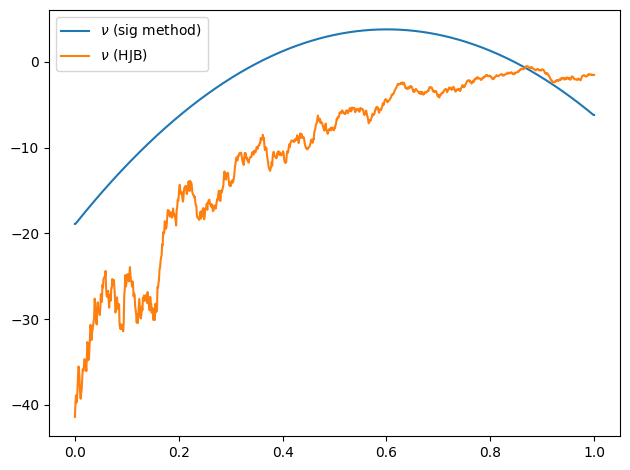

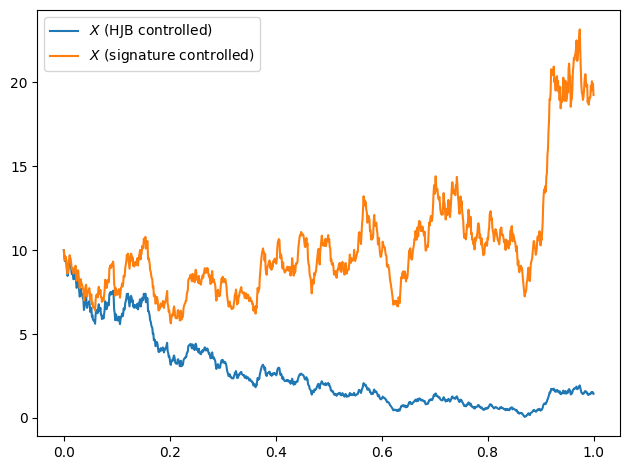

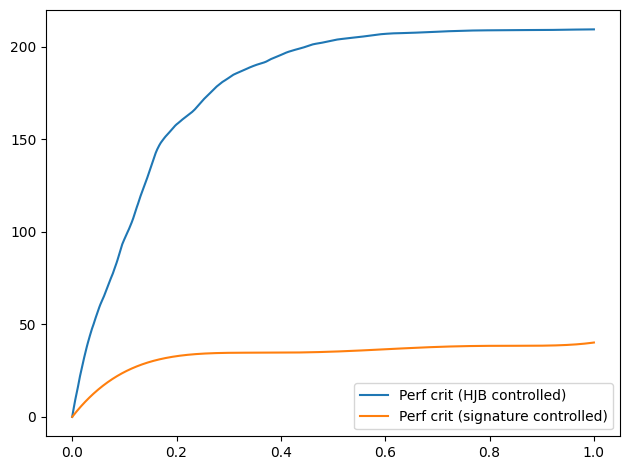

In [16]:
nsim = 0

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$ (sig method)')
plt.plot(env.timesteps, env_hjb.nu[:,nsim], label=r'$\nu$ (HJB)')
#plt.plot(env.timesteps, env_hjb_sig.nu[:,nsim], label=r'$\nu$ (HJB sig representation)', linestyle='-.')
#plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env_hjb.X[:,nsim], label=r'$X$ (HJB controlled)')
plt.plot(env.timesteps, env.X[:, nsim], label=r'$X$ (signature controlled)')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env_hjb.run_crit[:,nsim], label=r'Perf crit (HJB controlled)')
plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit (signature controlled)')
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
print(f'Performance criterion\nSig: {env.performance.mean()}')

Performance criterion
Sig: 3713.7739769475447


In [36]:
print(f'Performance criterion\nHJB: {env_hjb.performance.mean()}')

Performance criterion
HJB: 426.4672881604432


In [162]:
optimiser_1.value_fn(F, max_order_x = max_order_x, truncate_fn = True, max_order_fn = max_order_fn)

KeyboardInterrupt: 

In [ ]:
# # f_s_sig = problem1.sig_strag_dot_1(f_s, order = trunc_lev)
# # f_alpha_sig = problem1.sig_strag_dot_1(f_alpha, order = trunc_lev_1)
# # f_perf_crit = problem1.sig_strag_dot_1(p_perf, order = order)

# max_order = max(max_order_x, max_order_fn)

# nsim = 1

# LF = optimiser_1.LF(optimiser_1.F, max_order = max_order_x)
# p_perf = optimiser_1.p_perf
# p_perf_run = optimiser_1.p_perf_run

# f_x_sig = lqproblem.sig_strag_dot_2(LF, order = max_order_x)
# f_perf_crit_run = lqproblem.sig_strag_dot_2(p_perf_run, order = max_order_fn)

# X_sig = np.zeros((env.Nt+1,))
# perf_hist = np.zeros((env.Nt+1,))

# W_sig = np.zeros(((env.dim**(max_order+1) - env.dim)//(env.dim - 1),))

# X_sig[0] = f_x_sig(env,W_sig,dim,0)
# perf_hist[0] = f_perf_crit_run(env,W_sig,dim,0)

# # S_sig = f_s_sig(env)
# # alpha_hat_sig = f_alpha_sig(env)
# # perf_hist = f_perf_crit(env)

# for it in range(1,env.Nt+1):
#     path_increment = np.array([env.timesteps[it]-env.timesteps[it-1], env.W[it,nsim]-env.W[it-1,nsim]])
#     W_sig[:] = iisignature.sigjoin(W_sig[:], path_increment, max_order)
#     X_sig[it] = f_x_sig(env,W_sig,dim,it)
#     perf_hist[it] = f_perf_crit_run(env,W_sig,dim,it)
#     #S_sig[it,:] = strag_sig(env,it)

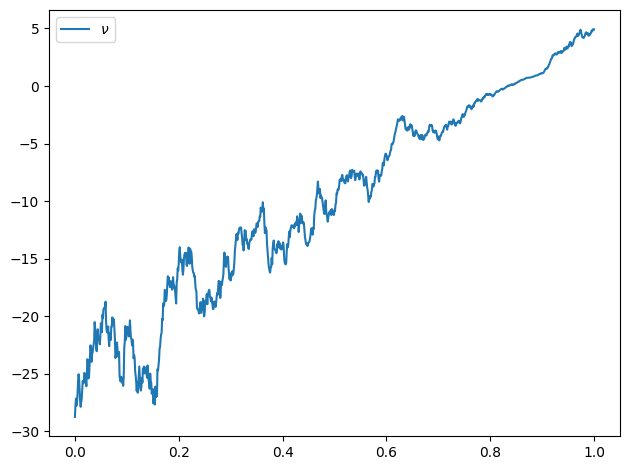

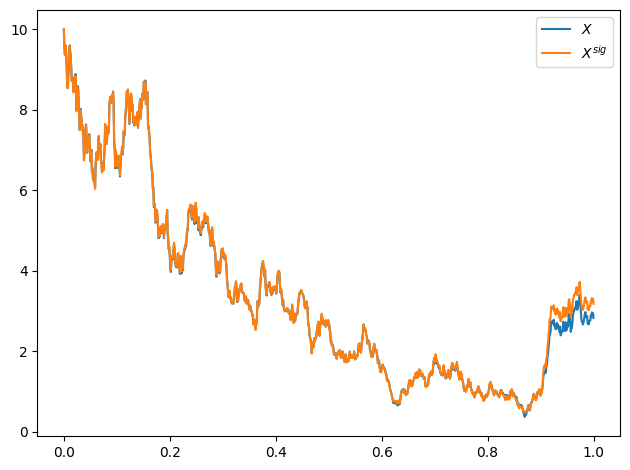

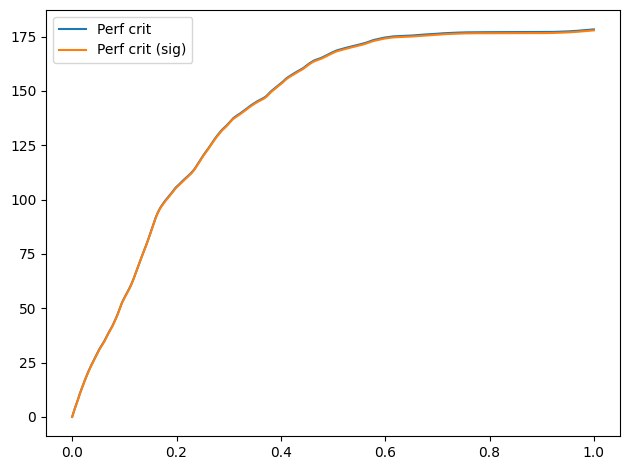

In [65]:
nsim = 0

max_order = max(max_order_x, max_order_fn)

LF = optimiser_1.LF(optimiser_1.F, max_order = max_order_fn//2)
p_perf, p_perf_run= optimiser_1.p_perf(optimiser_1.F, max_order = max_order_fn, return_running = True)

f_x_sig = lqproblem.sig_strag_dot_2(LF, order = max_order_x)
f_perf_crit_run = lqproblem.sig_strag_dot_2(p_perf_run, order = max_order_fn)

X_sig = np.zeros((env.Nt+1,))
perf_hist = np.zeros((env.Nt+1,))

W_sig = np.zeros(((env.dim**(max_order+1) - env.dim)//(env.dim - 1),))

X_sig[0] = f_x_sig(env,W_sig,dim,0)
perf_hist[0] = f_perf_crit_run(env,W_sig,dim,0)

# S_sig = f_s_sig(env)
# alpha_hat_sig = f_alpha_sig(env)
# perf_hist = f_perf_crit(env)

for it in range(1,env.Nt+1):
    path_increment = np.array([env.timesteps[it]-env.timesteps[it-1], env.W[it,nsim]-env.W[it-1,nsim]])
    W_sig[:] = iisignature.sigjoin(W_sig[:], path_increment, max_order)
    X_sig[it] = f_x_sig(env,W_sig,dim,it)
    perf_hist[it] = f_perf_crit_run(env,W_sig,dim,it)
    #S_sig[it,:] = strag_sig(env,it)

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.X[:,nsim], label=r'$X$')
plt.plot(env.timesteps, X_sig[:], label=r'$X^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit')
plt.plot(env.timesteps[:], perf_hist[:], label=r'Perf crit (sig)')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# with open('F_optimised_problem2.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()

In [ ]:
LF.order